# Régression sur le prix des annonces Airbnb à Paris

**Question** : les Jeux olympiques et paralympiques de 2024 ont-ils fait monter le prix des annonces Airbnb situées près des sites de compétition ?

**Difficulté** : les sites sont placés dans des lieux touristiques (tour Eiffel, Concorde, Invalides…), où les prix sont élevés et évoluent selon la saison, avec ou sans Jeux. Comparer simplement les prix près des sites et loin des sites, ou avant et pendant les Jeux, mélange donc l'effet des Jeux avec l'emplacement et la saison.

**Démarche :**
1. **Prime près des sites** : à caractéristiques égales, une annonce proche d'un site est-elle plus chère, et cet écart est-il plus fort en 2024 qu'en 2026, année sans Jeux ?
2. **Triple différence** : on suit les mêmes annonces de juin à septembre, et on compare l'évolution des annonces proches à celle des annonces éloignées, en 2024 et en 2026. Le supplément de 2024 est une estimation d'un effet relatif des Jeux sous une hypothèse de tendances comparables.

**Données** : relevés mensuels Inside Airbnb (juin à septembre 2024 et 2026) et liste des sites de compétition du ministère chargé des Sports.

## 0. Préparation

- **Relevés** : un relevé Inside Airbnb par mois, de juin à septembre, en 2024 (année des Jeux) et en 2026 (année de comparaison, sans Jeux). Chaque relevé est une photo de toutes les annonces parisiennes à une date donnée.
- **Sites de compétition** : on garde **tous les sites**, olympiques et paralympiques, y compris hors de Paris : une annonce du 18e peut être plus proche du Stade de France que d'un site parisien.

**Définition du prix** : le prix affiché est le prix par nuit, en dollars, d'un devis pour le premier séjour disponible. Une absence de prix n'identifie pas à elle seule une annonce complète ; les valeurs manquantes sont exclues de l'estimation.

**Pourquoi le log du prix** : on modélise $\log(\text{prix})$ plutôt que le prix. Un coefficient $\beta$ se lit alors comme un écart en pourcentage : $(e^{\beta} - 1) \times 100$ %, soit environ $\beta \times 100$ % quand $\beta$ est petit. Cela a deux avantages : un écart de 10 % a le même sens pour un studio à 80 $ et un appartement à 400 $, et le résultat ne dépend pas de la monnaie.

In [1]:
import sys
from pathlib import Path
# Accès aux modules de src/, que le notebook soit lancé depuis notebooks/ ou depuis la racine
sys.path.insert(0, str(next(p for p in (Path("../src"), Path("src")) if p.is_dir()).resolve()))

from regression_lineaire import (
    charger_donnees_regression, regression_hedonique,
    construire_panel, effectifs_panel, regression_panel,
)

releves_regression, sites_regression = charger_donnees_regression()
print(f"{len(sites_regression)} sites ; huit relevés 2024/2026 préparés.")

44 sites ; huit relevés 2024/2026 préparés.


### Distances et groupes d'annonces voisines

**Distance au site le plus proche** : on calcule la distance « à vol d'oiseau » sur la sphère terrestre avec la formule de Haversine. Pour deux points de latitudes $\varphi_1, \varphi_2$ et de longitudes $\lambda_1, \lambda_2$ (en radians), avec $R = 6\,371$ km le rayon de la Terre :

$$d = 2R \arcsin\left(\sqrt{\sin^2\left(\frac{\varphi_2 - \varphi_1}{2}\right) + \cos\varphi_1 \cos\varphi_2 \sin^2\left(\frac{\lambda_2 - \lambda_1}{2}\right)}\right)$$

Pour chaque annonce, on calcule la distance à tous les sites et on garde la plus petite.

**Carrés de 500 m** : les prix de deux annonces voisines ne sont pas indépendants (même rue, même vue, mêmes commerces), et la proximité d'un site est la même pour tout un quartier. Si on traitait chaque annonce comme une information indépendante, on surestimerait la précision des résultats : les intervalles de confiance seraient trop étroits. On découpe donc Paris en **carrés d'environ 500 m de côté** et on calcule des **erreurs standard regroupées** (« clustered ») par carré : on autorise les annonces d'un même carré à être corrélées entre elles.

## 1. Première idée : la prime de prix près des sites, en 2024 et en 2026

**Idée** : comparer, dans un même relevé, le prix d'annonces semblables (même taille, même type, même arrondissement…) proches et loin d'un site. C'est une **régression hédonique** : le prix d'un logement est expliqué par ses caractéristiques, et on isole celle qui nous intéresse, la proximité d'un site.

$$\log(\text{prix}_i) = \beta_1 \cdot \mathbb{1}[< 1\text{ km}]_i + \beta_2 \cdot \mathbb{1}[1\text{-}3\text{ km}]_i + X_i'\theta + \mu_{\text{arrondissement}(i)} + \varepsilon_i$$

- $\mathbb{1}[< 1\text{ km}]_i$ vaut 1 si l'annonce $i$ est à moins de 1 km d'un site, 0 sinon (de même pour 1 à 3 km). La **référence** est « plus de 3 km ».
- $X_i$ regroupe les **contrôles** : type de logement, nombre de voyageurs, de chambres et de salles de bain, note et nombre d'avis, Superhôte, nombre minimum de nuits, hôte qui gère plusieurs annonces, distance au centre de Paris. Les annonces sans note reçoivent la note moyenne et une indicatrice « sans note », pour ne pas les retirer.
- $\mu_{\text{arrondissement}}$ est un **effet fixe arrondissement** : une constante propre à chaque arrondissement, qui absorbe tout ce qui rend un arrondissement plus cher qu'un autre. On compare donc des annonces du même arrondissement.
- **Lecture de $\beta_1$** : à caractéristiques égales et dans le même arrondissement, une annonce à moins de 1 km d'un site coûte $(e^{\beta_1} - 1) \times 100$ % de plus qu'une annonce à plus de 3 km.

Les 1 % de prix les plus bas et les plus hauts sont retirés (certaines annonces affichent des prix aberrants).

**Tableaux affichés** : le premier donne la prime près des sites et le test ci-dessous ; le second donne le coefficient $\hat\beta$ de **chaque variable** dans les quatre régressions (sur le log du prix, donc ≈ écart en % divisé par 100 ; étoiles : \*\*\* p < 0,01, \*\* p < 0,05, \* p < 0,1). Les 20 effets fixes arrondissement et la constante ne sont pas affichés. Pour le type de logement, la référence est « Entire home/apt ». La réservation instantanée est retirée des deux années : une information manquante en 2026 ne doit pas être codée comme fausse.

**Test 2024 contre 2026** : on réunit les deux années pour un même mois et on ajoute une interaction avec l'indicatrice $\mathbb{1}[2024]$ :

$$\log(\text{prix}_i) = \beta_1 \cdot \mathbb{1}[< 1\text{ km}]_i + \eta_1 \cdot \mathbb{1}[< 1\text{ km}]_i \cdot \mathbb{1}[2024]_i + \dots$$

$\beta_1$ est alors la prime en 2026 et $\eta_1$ l'écart de prime entre 2024 et 2026. Si les Jeux avaient ajouté une prime près des sites, $\eta_1$ serait positif ; une absence de différence significative reste compatible avec une prime de localisation, sans prouver que tous les facteurs omis sont neutralisés.

**Limite** : dans un relevé, $\beta_1$ mesure une corrélation entre proximité et prix, pas un effet causal. Des quartiers proches des sites peuvent être plus chers pour d'autres raisons que les contrôles ne captent pas (vue, attractivité). D'où la partie 2, qui suit les mêmes annonces dans le temps.

In [2]:
primes_regression, coefficients_regression = regression_hedonique(releves_regression, sites_regression)
display(primes_regression)
display(coefficients_regression)

prime 2024 (%)  p 2024  prime 2026 (%)  p 2026  \
mois    tranche                                                         
juin    moins de 1 km           5.428   0.024           5.986   0.042   
        1 à 3 km                1.700   0.325           1.192   0.507   
juillet moins de 1 km           3.827   0.065           3.965   0.133   
        1 à 3 km                0.134   0.923          -0.141   0.929   

                       écart relatif 2024 / 2026 (%)  p écart  
mois    tranche                                                
juin    moins de 1 km                          0.104    0.947  
        1 à 3 km                               0.162    0.905  
juillet moins de 1 km                         -2.084    0.141  
        1 à 3 km                              -1.225    0.326

,juin 2024,juin 2026,juillet 2024,juillet 2026
distance au site : moins de 1 km,0.053**,0.058**,0.038*,0.039
distance au site : 1 à 3 km,0.017,0.012,0.001,-0.001
type : Hotel room,0.486***,0.222***,0.246***,0.154**
type : Private room,-0.167***,-0.186***,-0.191***,-0.207***
type : Shared room,-0.449***,-0.794***,-0.398***,-0.754***
dist_centre_km,-0.094***,-0.098***,-0.080***,-0.084***
accommodates,0.136***,0.139***,0.111***,0.129***
bedrooms,0.158***,0.114***,0.198***,0.128***
bathrooms,0.091***,0.108***,0.111***,0.107***
note,0.149***,0.172***,0.167***,0.183***


## 2. Suivre les mêmes annonces : panel de l'été et groupes

**Panel** : on empile les relevés de juin à septembre 2024 et 2026. Une même annonce apparaît plusieurs fois, une fois par mois : on peut donc suivre **l'évolution de son prix**, et plus seulement comparer des annonces différentes.

**Calendrier 2024** : juin est collecté du 11 au 14 juin (avant les Jeux), juillet du 14 au 28 juillet (surtout du 16 au 18, juste avant l'ouverture du 26 juillet), août du 9 au 15 août (pendant les Jeux olympiques) et septembre du 6 au 13 septembre (à la fin des Jeux paralympiques et après leur clôture). **Juin sert de mois de référence.**

**Deux groupes** :
- un **groupe proche** (« traité ») : moins de 1 km d'un site ;
- un **groupe témoin** : plus de 2 km. Le seuil de 3 km laissait trop peu d'annonces (5 %). Les annonces entre 1 et 2 km, ni vraiment proches ni vraiment loin, sont retirées.

**Choix pratiques** :
- Airbnb décale légèrement la position affichée des logements d'un relevé à l'autre : on fixe une position par annonce (la médiane), qui donne son groupe et son carré de 500 m.
- Les 1 % de prix les plus bas et les plus hauts sont retirés avec des **bornes communes aux quatre mois** d'une même année. Avec des bornes propres à chaque mois, on effacerait justement les hausses de l'été.

In [3]:
panel_regression = construire_panel(releves_regression, sites_regression)
display(effectifs_panel(panel_regression))

,proche,témoin
annee,,
2024,22915,35544
2026,18640,26674


## 3. Triple différence : l'été 2024 comparé à l'été 2026

**Étape par étape :**
1. **Première différence** (dans le temps) : de combien le prix d'une annonce change-t-il entre juin et août ?
2. **Deuxième différence** (proches contre témoins) : ce changement est-il plus fort pour les annonces proches des sites ? C'est la **différence de différences**. Elle retire tout ce qui touche toutes les annonces de la même façon (par exemple la hausse générale des prix en été).
3. **Troisième différence** (2024 contre 2026) : les quartiers proches des sites sont touristiques et ont leur propre saisonnalité, même sans Jeux. On calcule donc la même différence de différences en 2026, et on la retire de celle de 2024. Ce qui reste estime un supplément relatif en 2024, sous les hypothèses du modèle.

**Le modèle** :

$$\log(\text{prix}_{it}) = \sum_{m \in \{7,8,9\}} \Big[\gamma_m \cdot \text{proche}_i \cdot \mathbb{1}[\text{mois}=m] + \delta_m \cdot \text{proche}_i \cdot \mathbb{1}[\text{mois}=m] \cdot \mathbb{1}[2024]\Big] + \alpha_{i,\text{année}} + \lambda_t + \varepsilon_{it}$$

- $\text{proche}_i$ vaut 1 si l'annonce est dans le groupe proche, 0 si elle est dans le groupe témoin.
- $\alpha_{i,\text{année}}$ : **effet fixe annonce × année**, une constante propre à chaque annonce chaque année. Il absorbe tout ce qui ne change pas d'un mois à l'autre (taille, emplacement, qualité) : on ne compare donc une annonce qu'à elle-même.
- $\lambda_t$ : **effet fixe mois** (un par mois et par année). Il absorbe ce qui touche toutes les annonces le même mois (saison, hausse générale des prix).
- $\gamma_m$ : écart **habituel** d'évolution entre proches et témoins le mois $m$, par rapport à juin (la saisonnalité propre aux quartiers proches des sites, mesurée grâce à 2026).
- **$\delta_m$ : l'effet des Jeux**, c'est-à-dire ce que l'écart proches - témoins a de plus en 2024 qu'en 2026. En %, il vaut $(e^{\delta_m} - 1) \times 100$.

Les erreurs standard sont regroupées par carré de 500 m.

**Hypothèse** : sans les Jeux, l'écart d'évolution entre proches et témoins aurait été le même en 2024 et en 2026. **Limite** : si les prix de juin 2024 étaient déjà touchés par les Jeux, la référence est faussée et la référence peut déjà être affectée ; le sens du biais dépend de la réaction des deux groupes.

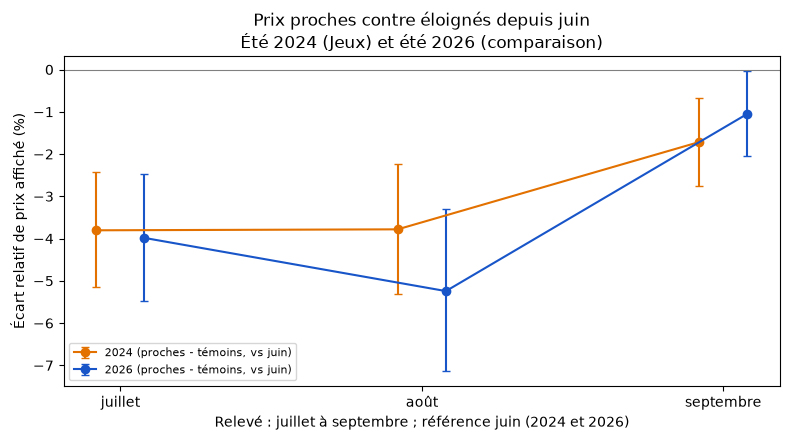

,supplément relatif 2024 (%),bas IC 95 %,haut IC 95 %,p-valeur
juillet,0.188,-1.054,1.445,0.768
août,1.542,-0.338,3.458,0.109
septembre,-0.676,-2.195,0.867,0.389


Effectifs réellement estimés : {'observations': 252900, 'annonces_années': 78025, 'cellules_spatiales': 346}


In [4]:
resultats_triple, figure_regression, diagnostic_regression = regression_panel(panel_regression)
display(figure_regression)
display(resultats_triple)
print("Effectifs réellement estimés :", diagnostic_regression)

### Lecture des résultats

Le graphique compare les trajectoires des annonces proches et éloignées par rapport à juin, séparément en 2024 et en 2026. Le tableau donne le supplément relatif propre à 2024. L'intervalle de confiance, et pas seulement le signe du coefficient, détermine si le résultat se distingue statistiquement de zéro.

Une p-valeur supérieure à 0,05 ne prouve pas l'absence d'effet. Le modèle vise un effet relatif près des sites ; il ne mesure pas une hausse qui toucherait tout Paris. Le rapport final interprète les valeurs réestimées ci-dessus.


## 4. Portée de la comparaison

La localisation touristique, la qualité des logements et la saisonnalité expliquent des écarts qui préexistent aux compétitions. Les contrôles et les effets fixes réduisent ces différences ; ils ne les effacent pas automatiquement.

La comparaison avec 2026 repose sur la stabilité de l'écart saisonnier entre groupes. Un seul mois de référence ne permet pas de vérifier suffisamment cette hypothèse. Les prix manquants, l'anticipation des Jeux et la diffusion de la demande hors des quartiers proches restent des limites.

Les prix sont affichés, pas payés. Le panel n'identifie ni les réservations ni les revenus des hôtes. Les estimations doivent être rapprochées des cartes, des effectifs et de la couverture des prix présentés dans le rapport final.
